# Linear Regression, Logistic Regression and K-Means

Based on Chapters 4 and 9 of *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd edition) by Aurélien Géron. Some of the code is adapted from the book's notebooks `04_training_linear_models.ipynb` and `09_unsupervised_learning.ipynb` (https://github.com/ageron/handson-ml3).

**Contents**

1. Linear Regression
2. Logistic Regression
3. K-Means

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# 1. Linear Regression

A linear model predicts a weighted sum of the input features, plus a bias term:

$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$$

Training the model means finding the values of $\theta$ that make the predictions as close as possible to the targets. For regression, we usually minimize the mean squared error:

$$\text{MSE}(\boldsymbol\theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

There are two ways to find these values: a direct formula (the Normal Equation), or step by step (Gradient Descent).

## 1.1 Some data

100 points around the line $y = 4 + 3x_1$, with some random noise:

In [2]:
np.random.seed(42)
m = 100  # number of instances
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

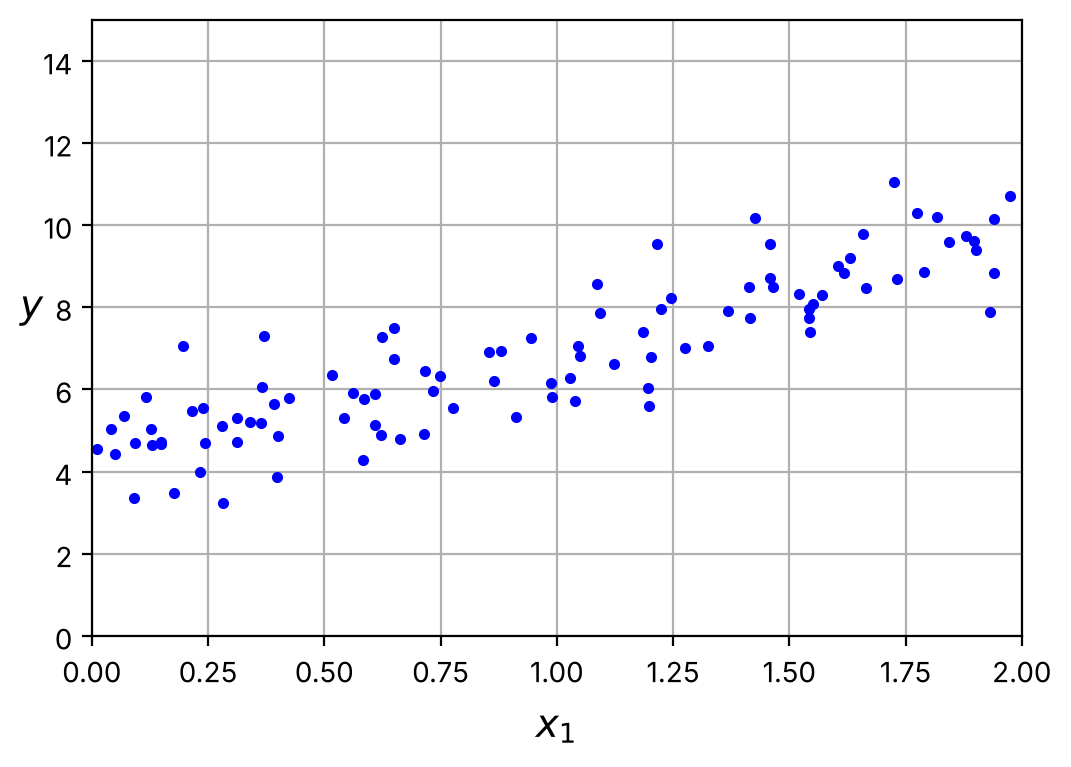

In [3]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

## 1.2 The Normal Equation

The Normal Equation gives the best $\theta$ directly:

$$\hat{\boldsymbol\theta} = (\mathbf{X}^T\mathbf{X})^{-1}\,\mathbf{X}^T\mathbf{y}$$

First we add $x_0 = 1$ to every instance, so that $\theta_0$ is treated like the other parameters:

In [4]:
X_b = np.c_[np.ones((m, 1)), X]  # add x0 = 1 to each instance
X_b[:3]

array([[1.        , 0.74908024],
       [1.        , 1.90142861],
       [1.        , 1.46398788]])

In [5]:
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_best

array([[4.21509616],
       [2.77011339]])

We were hoping for $\theta_0 = 4$ and $\theta_1 = 3$. Because of the noise we cannot get them exactly, but we are close. Now we can make predictions:

In [6]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b @ theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

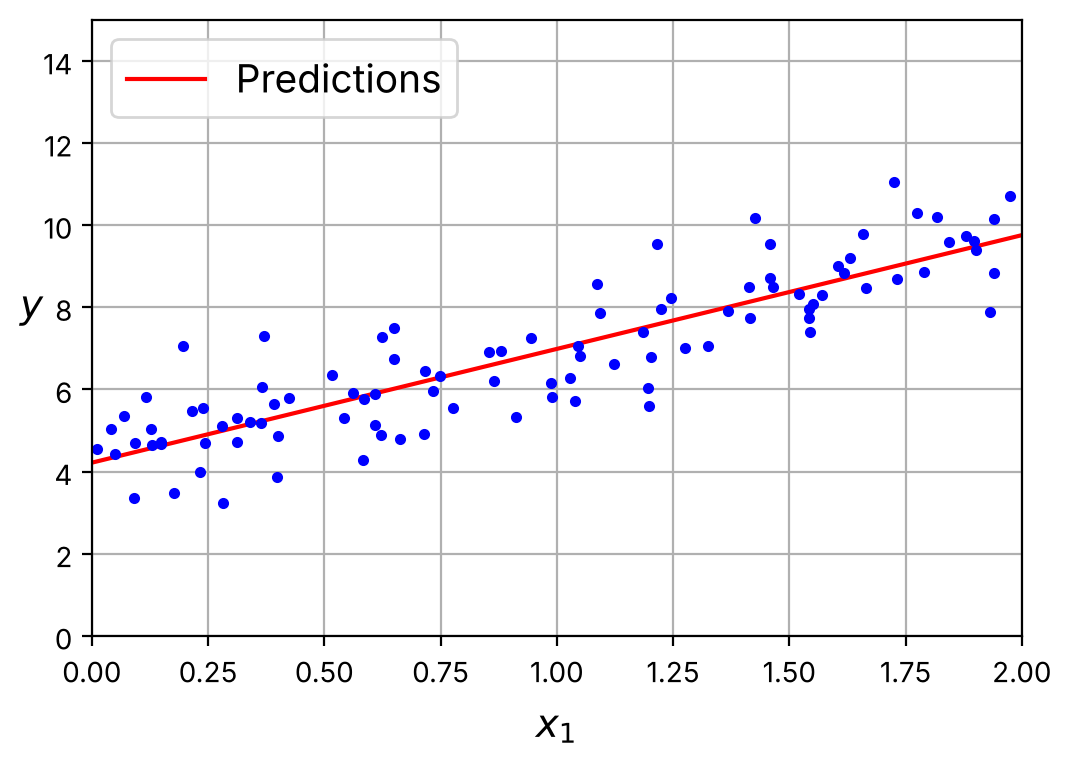

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.legend(loc="upper left")
plt.grid()
plt.show()

## 1.3 With Scikit-Learn

In [8]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

Same result. The bias term is stored in `intercept_` and the feature weights in `coef_`.

The Normal Equation gets slow when there are many features: inverting $\mathbf{X}^T\mathbf{X}$ costs between about $O(n^{2.4})$ and $O(n^3)$, where $n$ is the number of features. It also needs the whole training set in memory. Gradient Descent does not have these problems.

In [9]:
lin_reg.predict(X_new)

array([[4.21509616],
       [9.75532293]])

## 1.4 Batch Gradient Descent

Gradient Descent starts from random values of $\theta$ and improves them step by step. At each step it computes the gradient of the cost (the direction in which the cost increases fastest) and moves in the opposite direction:

$$\nabla_{\boldsymbol\theta}\,\text{MSE}(\boldsymbol\theta) = \frac{2}{m}\,\mathbf{X}^T(\mathbf{X}\boldsymbol\theta - \mathbf{y})$$

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}\,\text{MSE}(\boldsymbol\theta)$$

$\eta$ is the **learning rate**: the size of each step. This version is called *Batch* Gradient Descent because it uses the whole training set at every step.

In [10]:
eta = 0.1  # learning rate
n_epochs = 1000

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

theta

array([[4.21509616],
       [2.77011339]])

Exactly what the Normal Equation found.

## 1.5 The learning rate

The first 20 steps of Gradient Descent with three different learning rates (the lighter the line, the earlier the step):

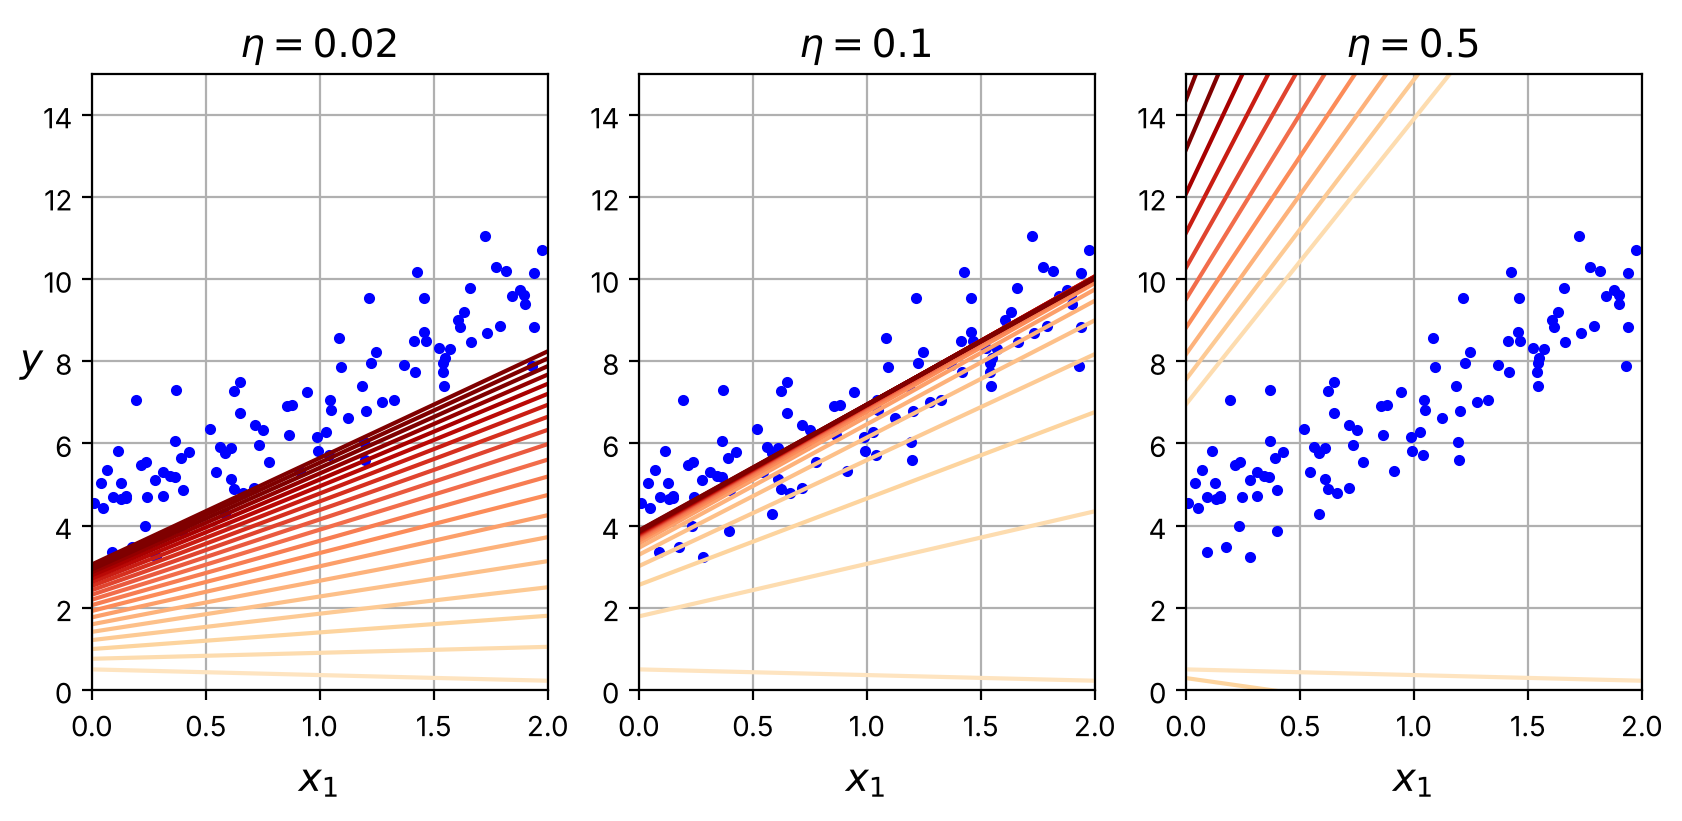

In [11]:
# extra code – plots the first 20 steps for a given learning rate
def plot_gradient_descent(theta, eta, n_steps=20):
    plt.plot(X, y, "b.")
    for step in range(n_steps):
        y_predict = X_new_b @ theta
        color = plt.cm.OrRd(step / n_steps + 0.15)
        plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")

np.random.seed(42)
theta = np.random.randn(2, 1)

plt.figure(figsize=(10, 4))
for i, eta in enumerate([0.02, 0.1, 0.5]):
    plt.subplot(1, 3, i + 1)
    plot_gradient_descent(theta, eta)
    if i == 0:
        plt.ylabel("$y$", rotation=0)
plt.show()

- $\eta = 0.02$: too small. After 20 steps the line is still far from the data, so we would need many more steps.
- $\eta = 0.1$: good. The line reaches the data in a few steps.
- $\eta = 0.5$: too large. Every step jumps further away, and the algorithm diverges.

Gradient Descent also works much better when all the features have a similar scale, so scale them first (for example with `StandardScaler`).

## 1.6 Stochastic and Mini-batch Gradient Descent

Batch Gradient Descent uses all the instances at every step, which is slow on a large training set. There are two faster versions:

| | Data used at each step | Notes |
|---|---|---|
| Batch GD | the whole training set | stable, but slow on large datasets |
| Stochastic GD | one random instance | fast but noisy; the learning rate is reduced gradually (a *learning schedule*) |
| Mini-batch GD | a small random batch | between the two; works well on GPUs |

Stochastic Gradient Descent:

In [12]:
n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)  # one instance, so no division by m
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients

theta

array([[4.21076011],
       [2.74856079]])

Only 50 passes over the data, and the result is close to the Normal Equation's. Scikit-Learn's `SGDRegressor` does the same:

In [13]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())  # y.ravel() because fit() expects a 1D target
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

Mini-batch Gradient Descent, with batches of 20 instances:

In [14]:
n_epochs = 50
batch_size = 20
eta = 0.1

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    shuffled_indices = np.random.permutation(m)
    for start in range(0, m, batch_size):
        batch = shuffled_indices[start : start + batch_size]
        xb, yb = X_b[batch], y[batch]
        gradients = 2 / batch_size * xb.T @ (xb @ theta - yb)
        theta = theta - eta * gradients

theta

array([[4.22023943],
       [2.7704472 ]])

# 2. Logistic Regression

Logistic Regression is a linear model for classification. It computes the same weighted sum as Linear Regression, then passes it through the **sigmoid** function to get a probability between 0 and 1:

$$\hat{p} = \sigma(\boldsymbol\theta^T\mathbf{x}) \qquad \sigma(t) = \frac{1}{1 + e^{-t}}$$

It predicts the positive class when $\hat{p} \ge 0.5$, which happens exactly when $\boldsymbol\theta^T\mathbf{x} \ge 0$.

## 2.1 The sigmoid function

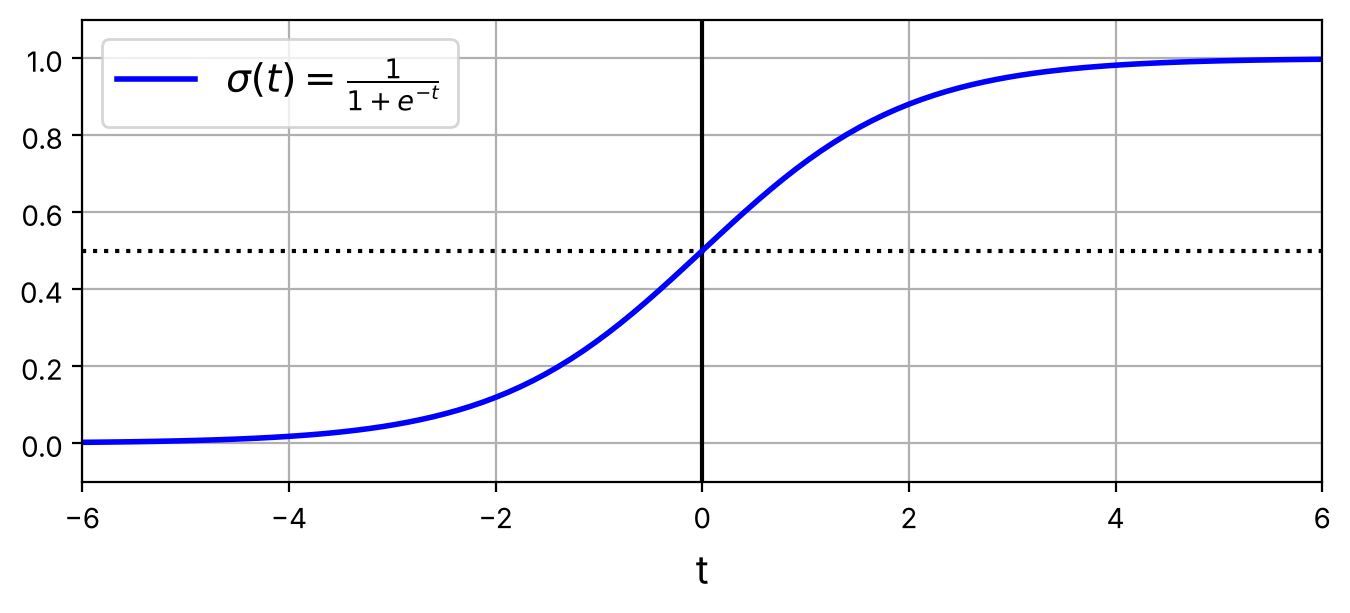

In [15]:
t = np.linspace(-6, 6, 100)
sig = 1 / (1 + np.exp(-t))

plt.figure(figsize=(8, 3))
plt.plot([-6, 6], [0.5, 0.5], "k:")
plt.plot([0, 0], [-0.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \frac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left")
plt.axis([-6, 6, -0.1, 1.1])
plt.grid()
plt.show()

## 2.2 The cost function (log loss)

For one instance, the cost is $-\log(\hat{p})$ if $y = 1$, and $-\log(1 - \hat{p})$ if $y = 0$. Over the whole training set:

$$J(\boldsymbol\theta) = -\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log\hat{p}^{(i)} + \left(1 - y^{(i)}\right)\log\left(1 - \hat{p}^{(i)}\right)\right]$$

There is no formula like the Normal Equation for this cost. But the cost is convex, so Gradient Descent will find the minimum.

Being confident and wrong is very expensive. The cost of one positive instance ($y = 1$) for different values of $\hat{p}$:

In [16]:
for p in [0.9, 0.6, 0.1]:
    print(f"p = {p}:  cost = {-np.log(p):.2f}")

p = 0.9:  cost = 0.11
p = 0.6:  cost = 0.51
p = 0.1:  cost = 2.30


## 2.3 The iris dataset

150 iris flowers from three species (setosa, versicolor and virginica), with four measurements for each flower:

In [17]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [18]:
iris.data.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [19]:
iris.target.head(3)  # the instances are not shuffled

0    0
1    0
2    0
Name: target, dtype: int64

In [20]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

## 2.4 Detecting Iris virginica from the petal width

A binary classifier: is this flower an Iris virginica or not?

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == "virginica"
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

The estimated probabilities for petal widths from 0 to 3 cm:

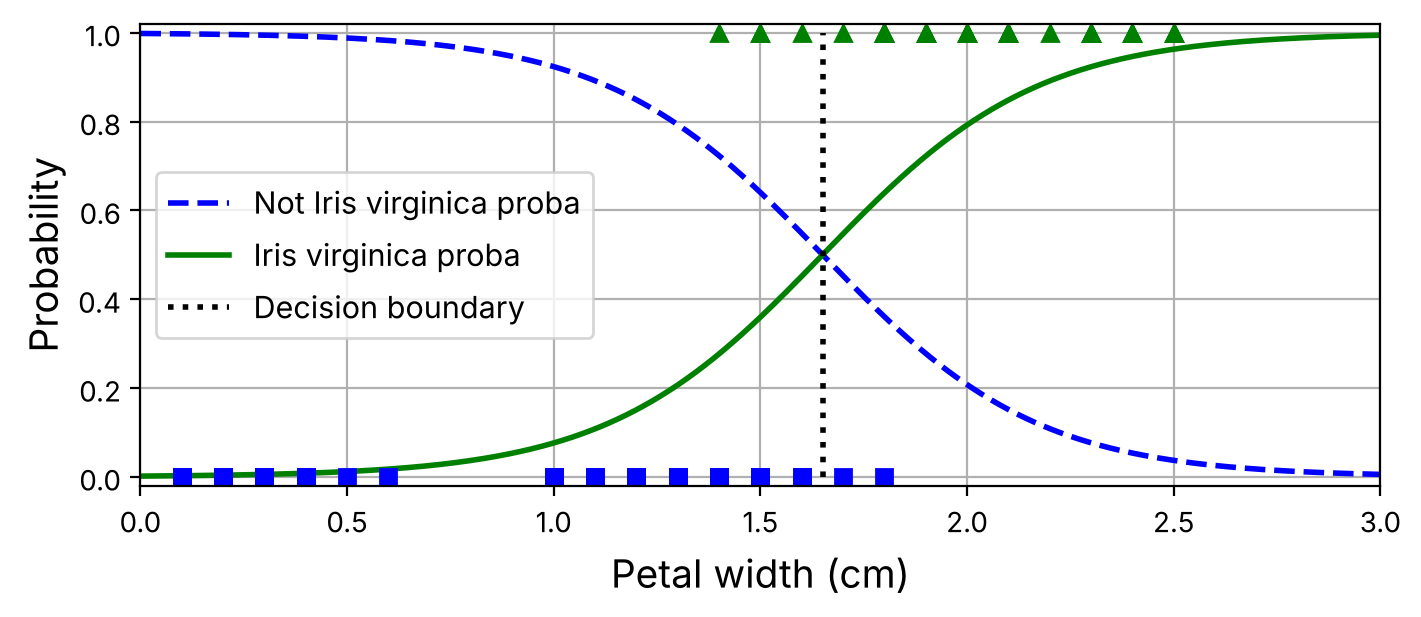

In [22]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(8, 3))
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2,
         label="Decision boundary")
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")
plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.legend(loc="center left", fontsize=11)
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()

In [23]:
round(float(decision_boundary), 2)

1.65

Above about 1.65 cm the probability of virginica is more than 50%, so the model predicts virginica.

Virginica petals are 1.4 to 2.5 cm wide, and the petals of the other two species 0.1 to 1.8 cm. Between 1.4 and 1.8 cm the classes overlap, and the model is not sure.

In [24]:
log_reg.predict([[1.7], [1.5]])

array([ True, False])

## 2.5 Changing the threshold

`predict()` uses a threshold of 0.5 on the probabilities given by `predict_proba()`. As in the classification section, moving the threshold trades precision for recall. The test set has 38 flowers, 12 of them virginica:

In [25]:
from sklearn.metrics import precision_score, recall_score

y_proba_test = log_reg.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    y_pred = y_proba_test >= threshold
    print(f"threshold = {threshold}:  "
          f"precision = {precision_score(y_test, y_pred):.2f}  "
          f"recall = {recall_score(y_test, y_pred):.2f}")

threshold = 0.3:  precision = 0.75  recall = 1.00
threshold = 0.5:  precision = 1.00  recall = 1.00
threshold = 0.7:  precision = 1.00  recall = 0.83


With a lower threshold the model finds every virginica, but some of its alarms are false. With a higher threshold every alarm is right, but it misses some virginicas.

## 2.6 Two features: a linear decision boundary

Now with the petal length and the petal width:

In [26]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == "virginica"
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(C=2, random_state=42)
log_reg.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",2
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following asp

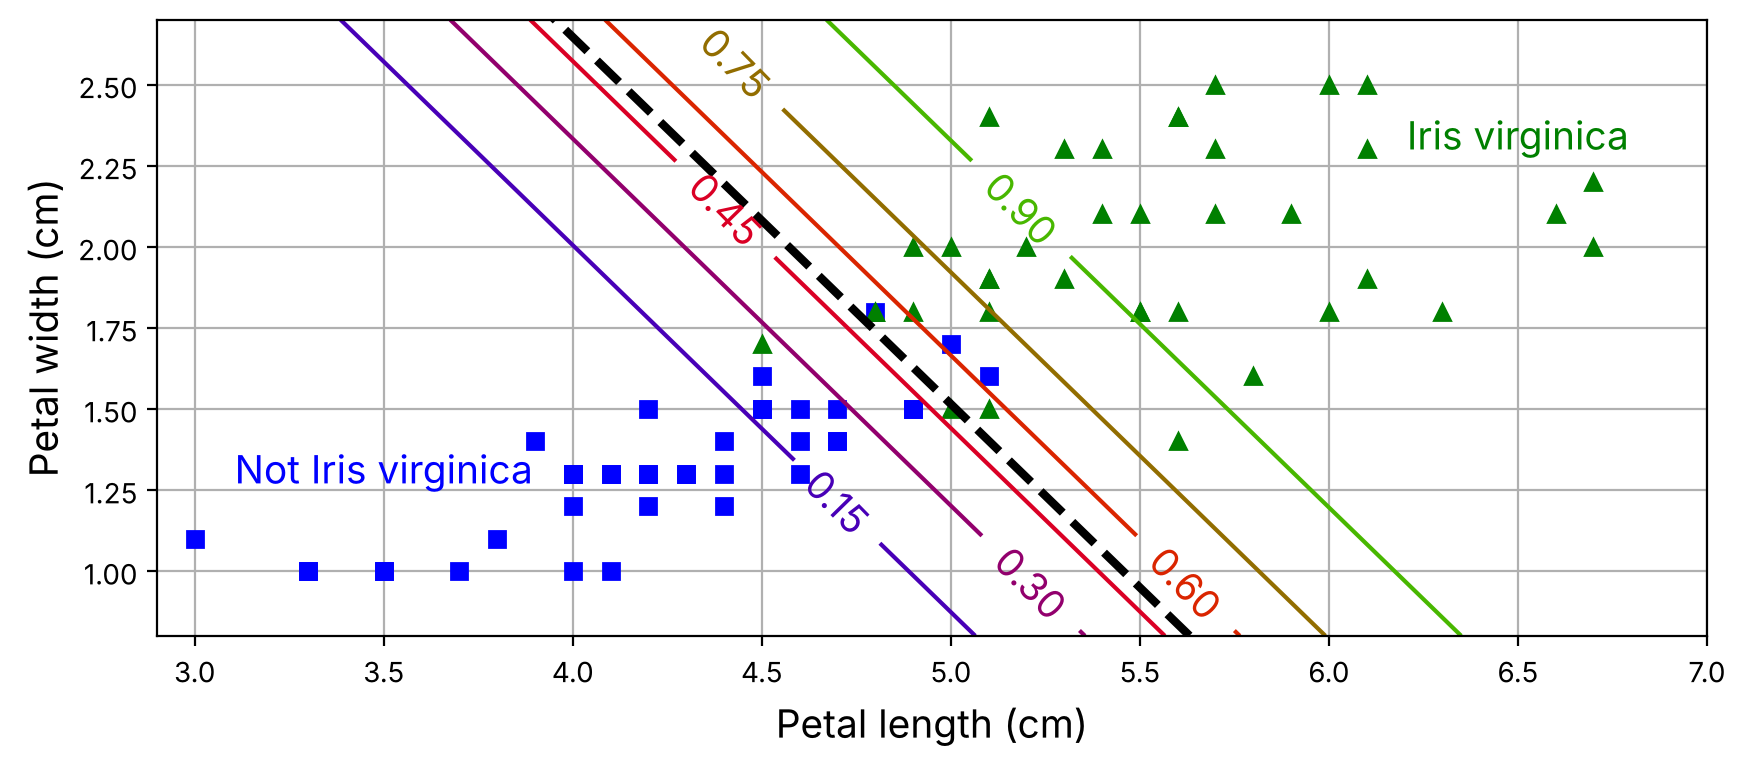

In [27]:
# extra code – probability contours and the decision boundary
x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500), np.linspace(0.8, 2.7, 200))
X_new = np.c_[x0.ravel(), x1.ravel()]  # one instance per point of the grid
y_proba = log_reg.predict_proba(X_new)
zz = y_proba[:, 1].reshape(x0.shape)

left_right = np.array([2.9, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0])
             / log_reg.coef_[0, 1])

plt.figure(figsize=(10, 4))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], "bs")
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], "g^")
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)
plt.clabel(contour, inline=1)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.27, "Not Iris virginica", color="b", ha="center")
plt.text(6.5, 2.3, "Iris virginica", color="g", ha="center")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.axis([2.9, 7, 0.8, 2.7])
plt.grid()
plt.show()

The dashed line is where the model is exactly 50% sure: the decision boundary. It is a straight line because the model is linear. The other lines show other probabilities (the value is written on each line).

`C` controls the regularization: the smaller `C`, the stronger the regularization. We will see regularization later.

## 2.7 Softmax Regression (more than two classes)

Logistic Regression can also handle several classes directly. For each class $k$, it computes a score $s_k(\mathbf{x}) = \left(\boldsymbol\theta^{(k)}\right)^T\mathbf{x}$. Then the **softmax** function turns the scores into probabilities that add up to 1:

$$\hat{p}_k = \frac{\exp\left(s_k(\mathbf{x})\right)}{\sum_{j=1}^{K}\exp\left(s_j(\mathbf{x})\right)}$$

The predicted class is the one with the highest probability. Scikit-Learn does this by itself when the target has more than two classes:

In [28]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target.values
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=30, random_state=42)
softmax_reg.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",30
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [29]:
softmax_reg.predict([[5, 2]])

array([2])

In [30]:
softmax_reg.predict_proba([[5, 2]]).round(2)

array([[0.  , 0.04, 0.96]])

A flower with petals 5 cm long and 2 cm wide: 96% virginica, 4% versicolor, 0% setosa. The decision regions:

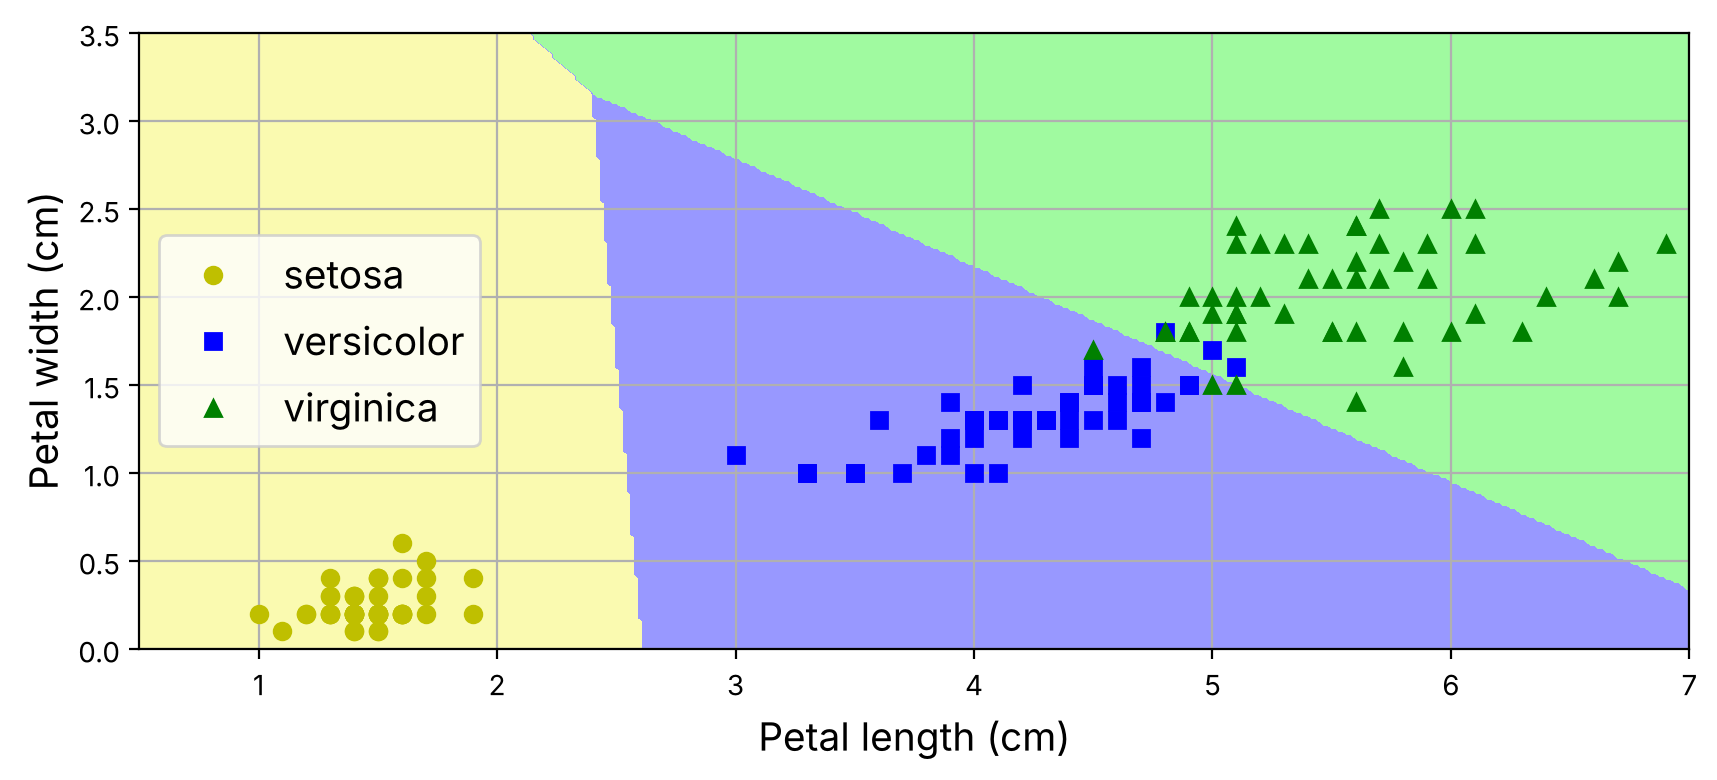

In [31]:
# extra code – decision regions of the three classes
from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
x0, x1 = np.meshgrid(np.linspace(0, 8, 500), np.linspace(0, 3.5, 200))
X_new = np.c_[x0.ravel(), x1.ravel()]
zz = softmax_reg.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.contourf(x0, x1, zz, cmap=custom_cmap)
for label, style in zip(range(3), ["yo", "bs", "g^"]):
    plt.plot(X[y == label, 0], X[y == label, 1], style, label=iris.target_names[label])
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(loc="center left")
plt.axis([0.5, 7, 0, 3.5])
plt.grid()
plt.show()

In [32]:
softmax_reg.score(X_test, y_test)

1.0

All 38 flowers of the test set are classified correctly.

# 3. K-Means

So far, every training instance had a label. In **clustering** there are no labels: the algorithm has to find groups of similar instances by itself.

K-Means needs the number of clusters $k$. It repeats two steps until the centroids stop moving:

1. assign every instance to the closest centroid;
2. move every centroid to the mean of the instances assigned to it.

## 3.1 Classification vs clustering

The same iris flowers, with and without the labels:

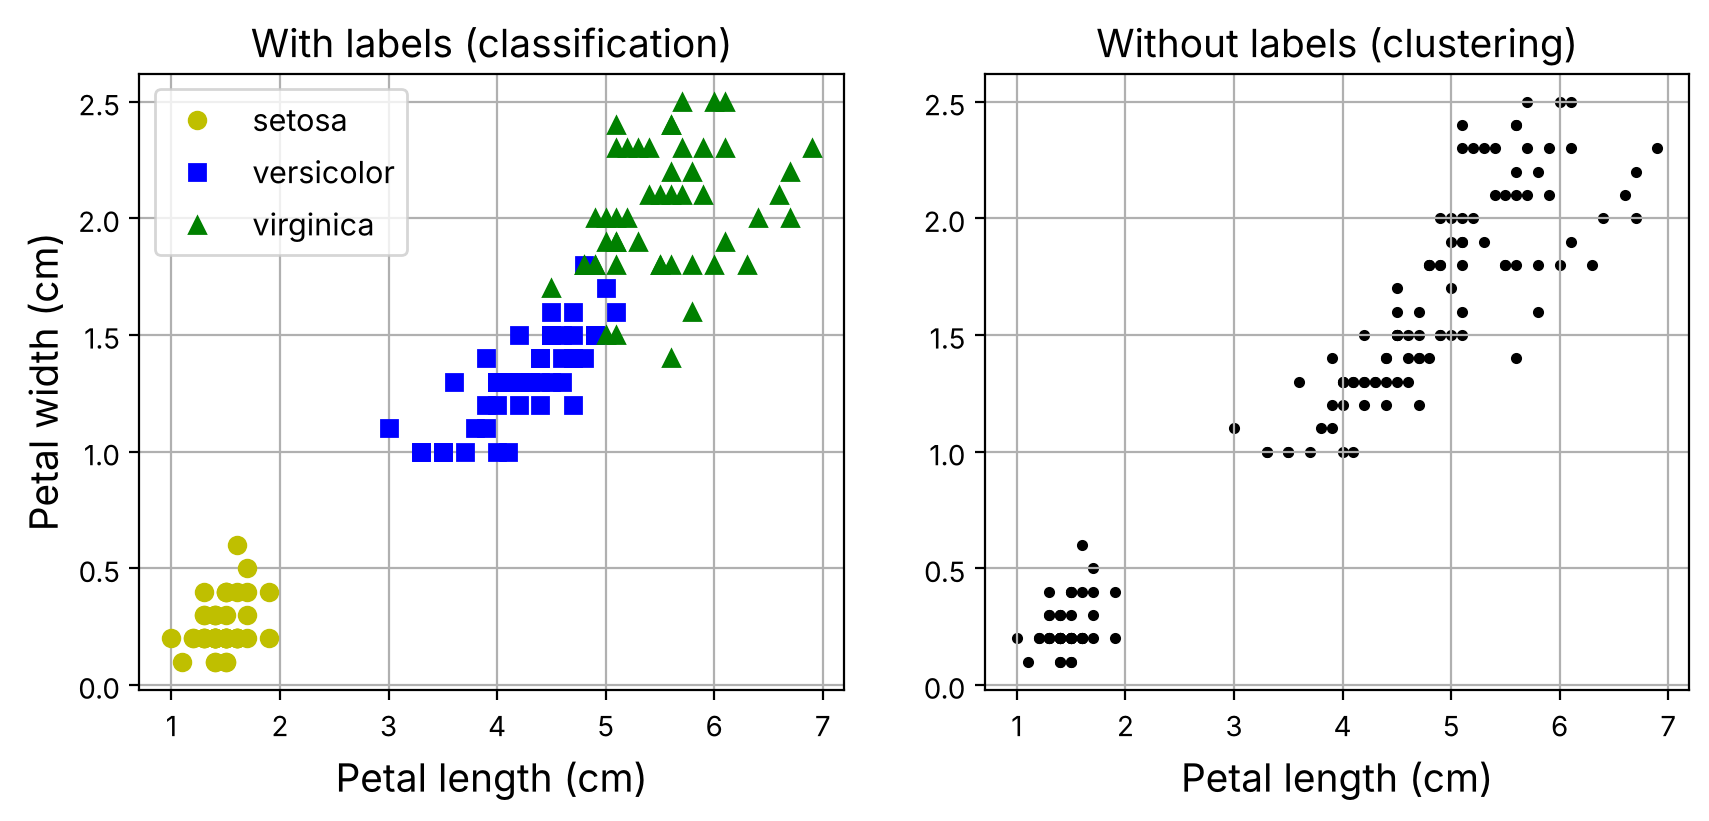

In [33]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target.values

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
for label, style in zip(range(3), ["yo", "bs", "g^"]):
    plt.plot(X[y == label, 0], X[y == label, 1], style, label=iris.target_names[label])
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(fontsize=11)
plt.title("With labels (classification)")
plt.grid()

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c="k", marker=".")
plt.xlabel("Petal length (cm)")
plt.title("Without labels (clustering)")
plt.grid()
plt.show()

Without the labels, setosa is clearly a separate group, but it is hard to tell where versicolor ends and virginica starts.

## 3.2 K-Means step by step

The two steps written with NumPy. We start from bad centroids on purpose, to watch them move:

In [34]:
def closest_centroid(X, centroids):
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)  # shape (150, 3)
    return distances.argmin(axis=1)

centroids = np.array([[1.0, 2.0], [4.0, 0.5], [7.0, 0.5]])  # bad starting points
history = [centroids]

for iteration in range(20):
    labels = closest_centroid(X, centroids)                    # step 1
    new_centroids = np.array([X[labels == k].mean(axis=0)      # step 2
                              for k in range(3)])
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids
    history.append(centroids)

print("Stopped after", iteration + 1, "iterations")
centroids

Stopped after 7 iterations


array([[1.462     , 0.246     ],
       [4.29259259, 1.35925926],
       [5.62608696, 2.04782609]])

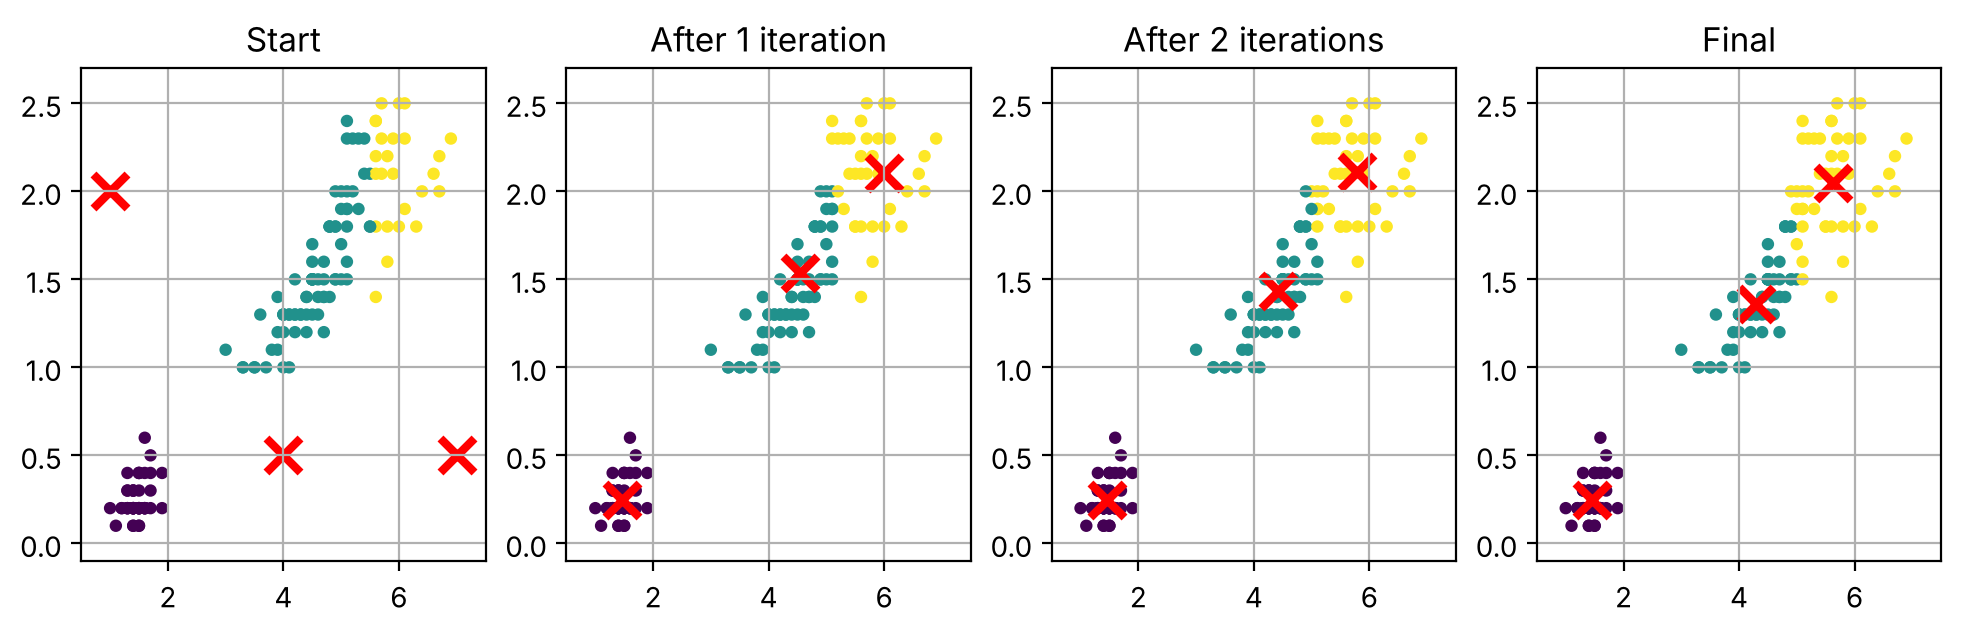

In [35]:
# extra code – the clusters at different iterations
steps = [0, 1, 2, len(history) - 1]
titles = ["Start", "After 1 iteration", "After 2 iterations", "Final"]

plt.figure(figsize=(12, 3.2))
for i, (step, title) in enumerate(zip(steps, titles)):
    plt.subplot(1, 4, i + 1)
    c = history[step]
    plt.scatter(X[:, 0], X[:, 1], c=closest_centroid(X, c), s=12)
    plt.scatter(c[:, 0], c[:, 1], marker="x", s=150, c="red", linewidths=3)
    plt.title(title, fontsize=12)
    plt.axis([0.5, 7.5, -0.1, 2.7])
    plt.grid()
plt.show()

Most of the work happens in the first iteration; after that the centroids only move a little.

## 3.3 K-Means with Scikit-Learn

In [36]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)
y_pred[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [37]:
kmeans.cluster_centers_

array([[5.59583333, 2.0375    ],
       [1.462     , 0.246     ],
       [4.26923077, 1.34230769]])

The cluster numbers are arbitrary: cluster 1 is not species number 1. Let's compare the clusters with the species that we hid from the algorithm:

In [38]:
import pandas as pd

pd.crosstab(iris.target_names[y], y_pred, rownames=["species"], colnames=["cluster"])

cluster,0,1,2
species,,,
setosa,0,50,0
versicolor,2,0,48
virginica,46,0,4


Setosa gets a cluster of its own. Versicolor and virginica are separated well too: only 6 of these 100 flowers end up in the other one's cluster.

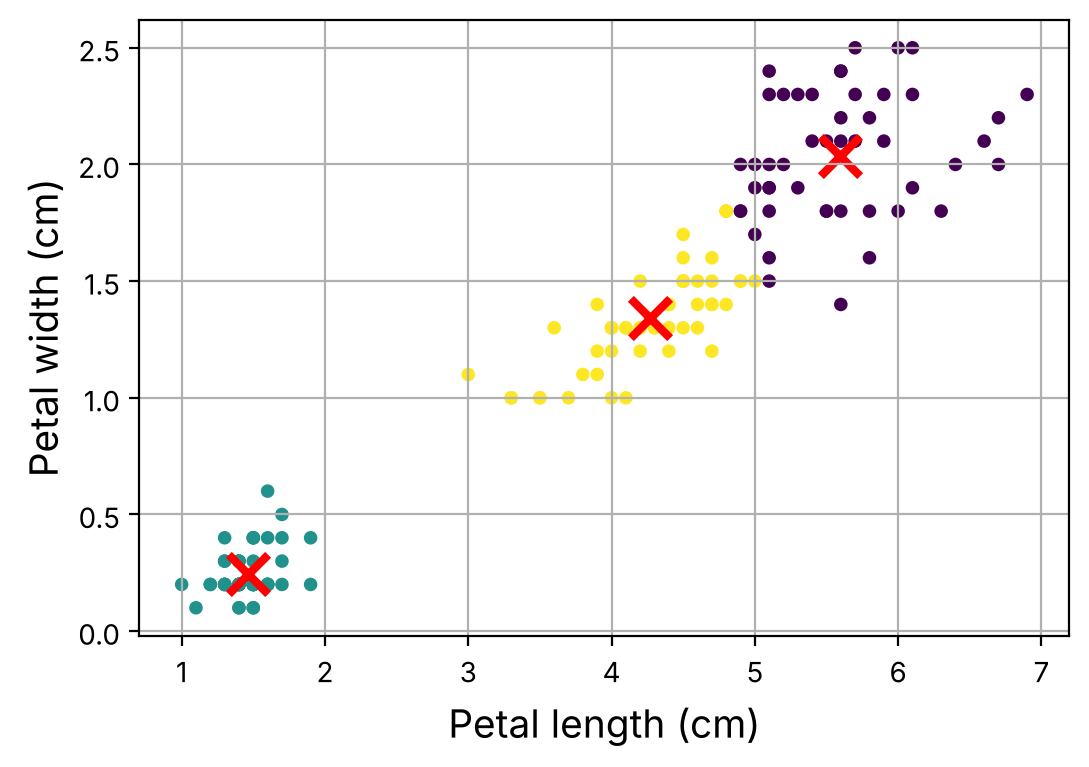

In [39]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, s=15)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker="x", s=200, c="red", linewidths=3)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.grid()
plt.show()

A new flower goes to the cluster of the closest centroid:

In [40]:
kmeans.predict([[1.5, 0.3], [4.5, 1.5], [6.0, 2.1]])

array([1, 2, 0], dtype=int32)

`transform()` gives the distance from a flower to every centroid:

In [41]:
kmeans.transform([[4.5, 1.5]]).round(2)

array([[1.22, 3.29, 0.28]])

Scikit-Learn starts from better centroids than our loop did (the *k-means++* method). With `n_init=10`, it also runs the algorithm 10 times and keeps the best result.

## 3.4 Choosing k: the inertia

The **inertia** is the sum of the squared distances between each instance and its centroid. Lower is better, but it always goes down when $k$ grows, so we look for the point where it stops dropping fast (the *elbow*):

In [42]:
kmeans.inertia_

31.37135897435897

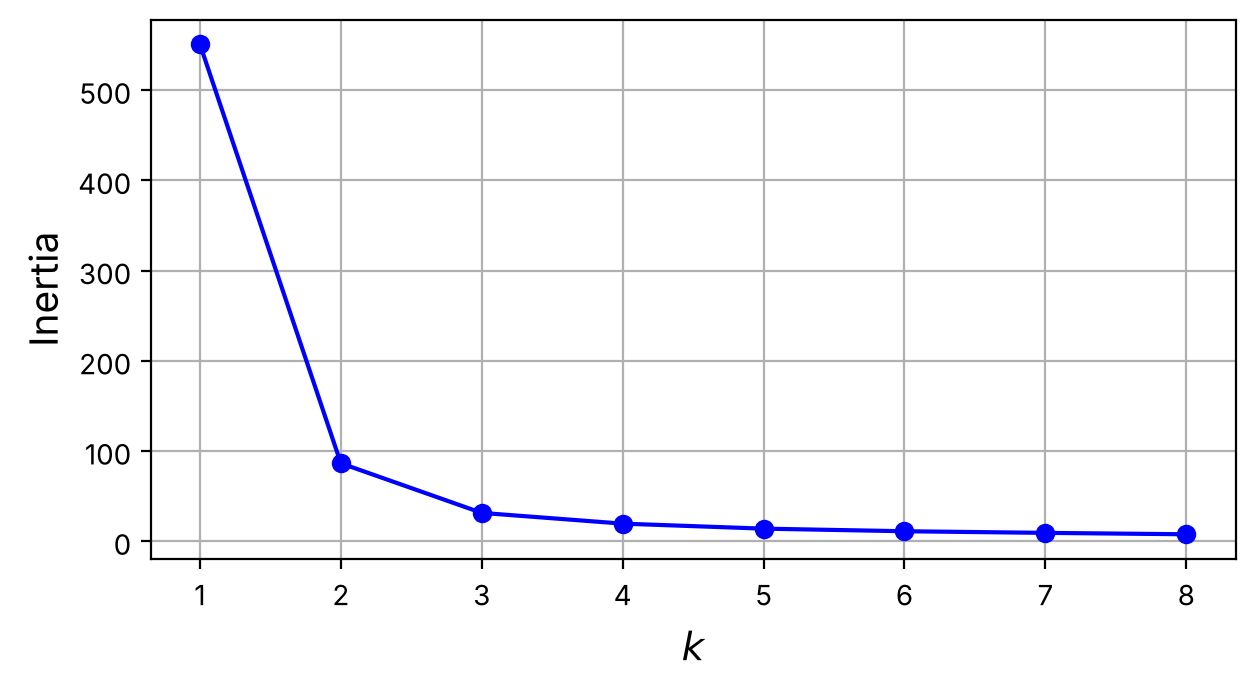

In [43]:
kmeans_per_k = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
                for k in range(1, 9)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 9), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.grid()
plt.show()

The curve bends sharply at $k = 2$, and a little less at $k = 3$.

## 3.5 Choosing k: the silhouette score

For each instance, the silhouette coefficient compares the mean distance to the other instances of its cluster with the mean distance to the instances of the nearest other cluster. It goes from −1 to +1, and higher is better. The silhouette score is its average over all the instances:

In [44]:
from sklearn.metrics import silhouette_score

silhouette_score(X, kmeans.labels_)

0.6604800083974887

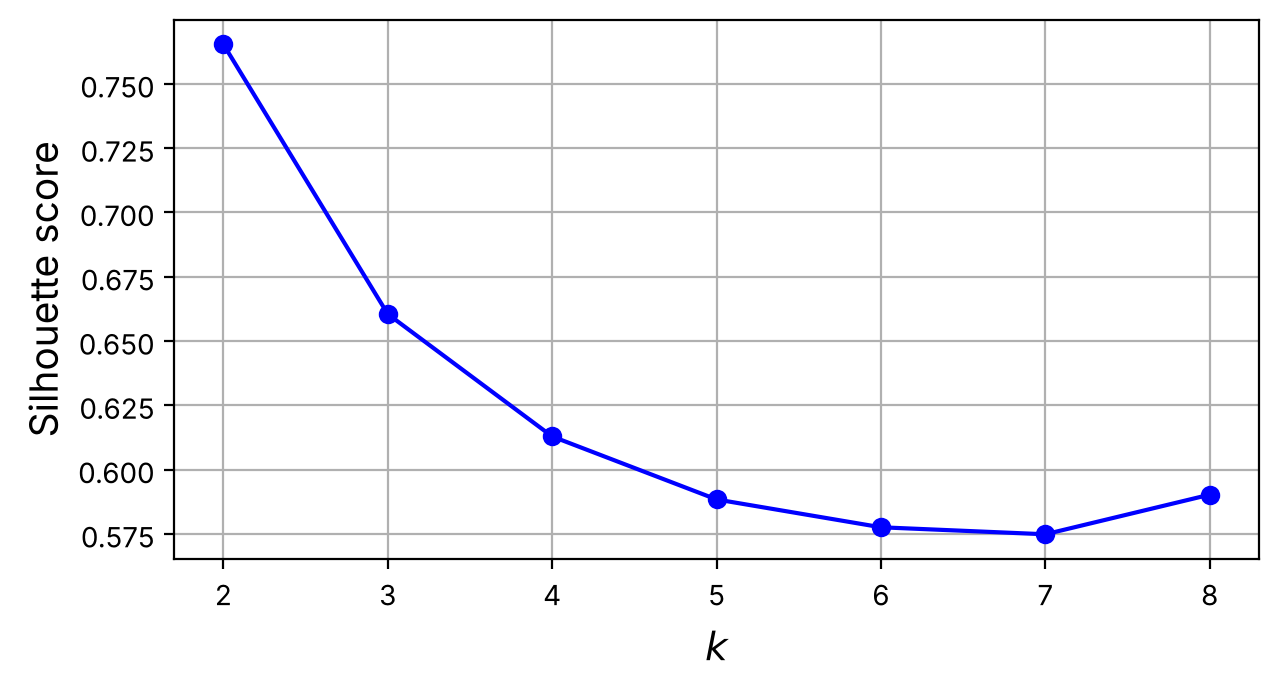

In [45]:
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

plt.figure(figsize=(7, 3.5))
plt.plot(range(2, 9), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.grid()
plt.show()

Both methods prefer $k = 2$: setosa against the rest. There are three species, but versicolor and virginica are close to each other, so the data alone suggests two groups. Clustering finds the groups that are in the data, which are not always the labels we have in mind.

## 3.6 Limits of K-Means

- You have to choose $k$.
- The result depends on the starting centroids. That is why Scikit-Learn runs it several times (`n_init`).
- It works best when the clusters are round and have similar sizes. It does badly with long or curved clusters.
- It uses distances, so scale the features first.

## 3.7 Color segmentation

Every pixel of an image is a point with three features: red, green and blue. If we cluster the pixels and replace each pixel with the color of its centroid, the image keeps only $k$ colors:

In [46]:
from sklearn.datasets import load_sample_image

image = load_sample_image("flower.jpg") / 255  # values between 0 and 1
image.shape

(427, 640, 3)

In [47]:
X_pixels = image.reshape(-1, 3)  # one row per pixel

segmented_images = []
n_colors = (10, 6, 4, 2)
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X_pixels)
    segmented_image = kmeans.cluster_centers_[kmeans.labels_]
    segmented_images.append(segmented_image.reshape(image.shape))

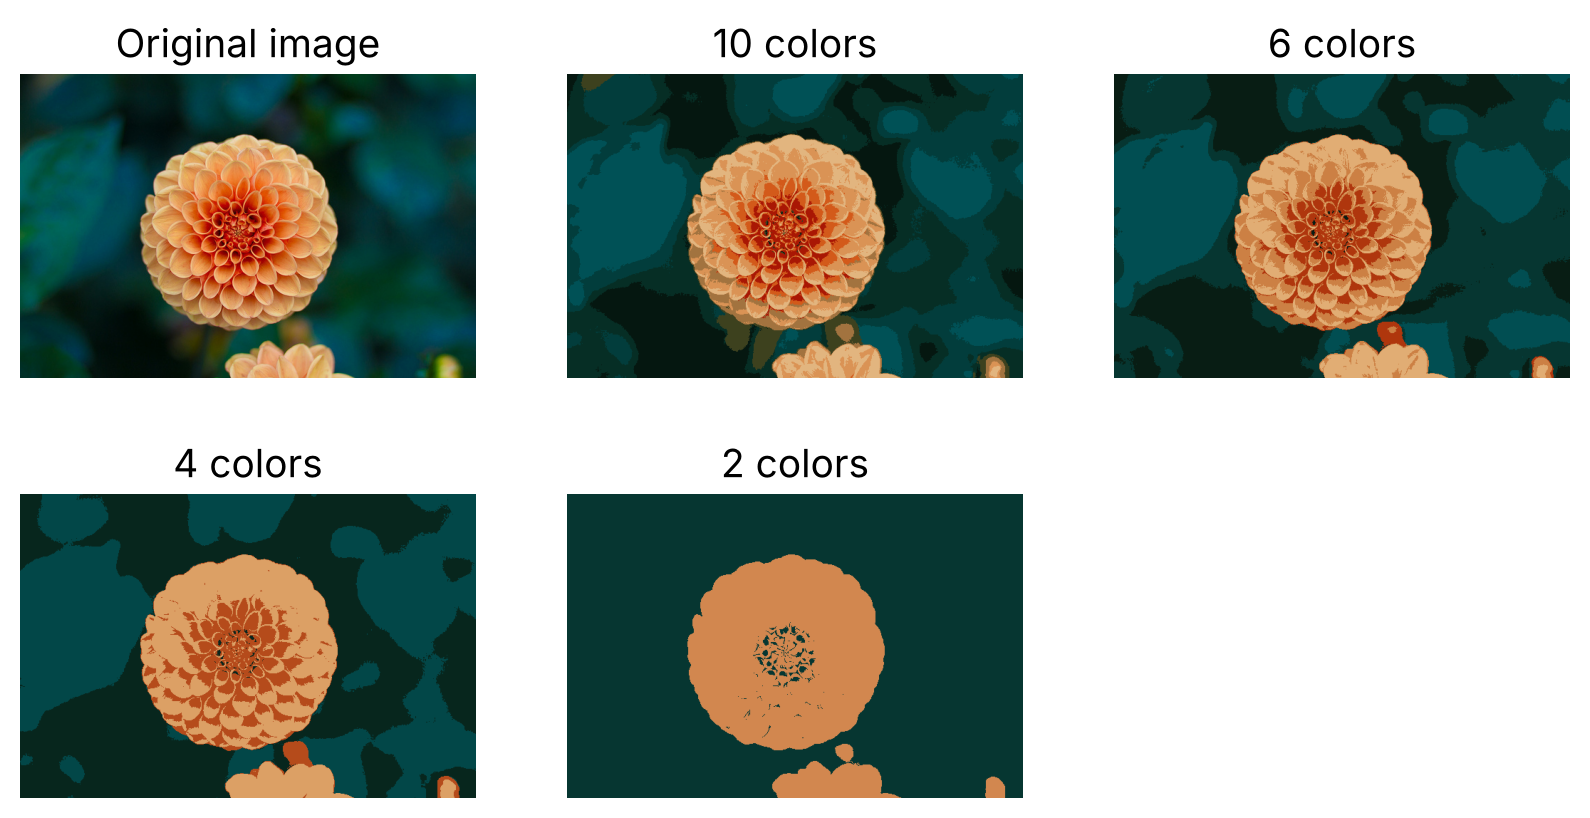

In [48]:
plt.figure(figsize=(10, 5))
plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original image")
plt.axis("off")
for i, n_clusters in enumerate(n_colors):
    plt.subplot(2, 3, 2 + i)
    plt.imshow(segmented_images[i])
    plt.title(f"{n_clusters} colors")
    plt.axis("off")
plt.show()

With only 2 colors, the flower is already separated from the dark background.

# Homework

1. In Part 1, run Batch Gradient Descent with `eta = 0.001`, then with `n_epochs = 50`. How far is `theta` from the Normal Equation's result each time?
2. Train the Softmax Regression model of Part 2 with `C = 0.1`, `C = 1` and `C = 30`, and plot the decision regions each time. What changes?
3. Run K-Means on all four iris features (scale them first with `StandardScaler`). Compare the crosstab and the silhouette scores with the ones in Part 3.